# Hybrid Task Cascade (HTC) baseline for RTS instance segmentation
**Input = 3 channels: `green`, `nir`, `relative_elevation`**  ·  **Split = your grouped 5-fold split**

Pure PyTorch/torchvision implementation of HTC (Chen et al., 2019) - no mmcv / mmdetection install needed.

What is implemented (all from the paper):
1. **3-stage cascade** box heads, IoU thresholds 0.5 / 0.6 / 0.7, stage loss weights 1 / 0.5 / 0.25, class-agnostic regression.
2. **Interleaved execution** - each stage's mask head sees the RoIs that stage's box head is trained on.
3. **Mask information flow** - `x_mask_t + G_t(m_{t-1})` using the 14x14 pre-deconv feature of the previous stages.
4. **Semantic segmentation branch** (fused FPN levels -> 4 conv -> logits + embedding) fused into box *and* mask RoI features.
5. Cascade inference: stage-averaged box scores, final-stage boxes, stage-averaged masks.

Two switches (`USE_SEM`, `INFO_FLOW`) let you reproduce the paper's ablation (Cascade Mask R-CNN -> +info flow -> +semantic = HTC) on RTS.

**Split layout this notebook expects** (matches your screenshots):
```
grouped_split/fold_k/data/{train,val,test}/{images/*.npz, annotations/instances_*.json}
competition_release/{metadata,train,test,tools,...}
```
Cell 4 prints and verifies the split (no image-id overlap between train/val/test, same local test set in every fold).

In [1]:
import os, sys, json, math, time, copy, random, glob, contextlib, io, subprocess, warnings
from collections import OrderedDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision

try:
    from pycocotools.coco import COCO
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pycocotools"], check=True)
    from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from pycocotools import mask as mask_utils

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

torch 2.11.0+cu128 | torchvision 0.26.0+cu128 | device cuda
Tesla T4


In [2]:
CFG = dict(
    # ---- data ----
    GS_ROOT=None,            # path of the 'grouped_split' folder; None = auto-detect
    CR_ROOT=None,            # path of 'competition_release'; None = auto-detect
    BANDS=["green", "nir", "relative_elevation"],   # the 3 input channels (order = channel order)
    FOLDS=[0],               # e.g. [0,1,2,3,4] to run every grouped fold
    MIN_SIZE=480, MAX_SIZE=960,   # chips are tiny (~150x290) -> upscale (short side 480)
    # ---- model ----
    BACKBONE="resnet50", PRETRAINED=True,
    USE_SEM=True,            # semantic branch + feature fusion   (HTC component 3)
    INFO_FLOW=True,          # mask information flow              (HTC component 2)
    STAGE_IOU=(0.5, 0.6, 0.7), STAGE_W=(1.0, 0.5, 0.25), SEM_W=1.0,
    # ---- training ----
    BATCH=4, EPOCHS=30, LR=1e-4, WD=1e-4, WARMUP=300, CLIP=10.0,
    AMP=True, WORKERS=2, VAL_EVERY=3, SEED=0,
    # ---- inference (official scorer uses maxDets=10) ----
    SCORE_THR=0.01, NMS_THR=0.5, MAX_DET=10,
    OUT_DIR="/kaggle/working/htc_rts" if os.path.isdir("/kaggle/working") else "./htc_rts",
)
os.makedirs(CFG["OUT_DIR"], exist_ok=True)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["SEED"])

In [3]:
def find_dir(name, roots=("/kaggle/input", "/content", "/mnt", "/workspace", ".")):
    for r in roots:
        if not os.path.isdir(r):
            continue
        for dp, dn, _ in os.walk(r):
            if os.path.basename(dp) == name:
                return dp
    return None

GS_ROOT = CFG["GS_ROOT"] or find_dir("grouped_split")
CR_ROOT = CFG["CR_ROOT"] or find_dir("competition_release")
print("GS_ROOT:", GS_ROOT); print("CR_ROOT:", CR_ROOT)
assert GS_ROOT and CR_ROOT, "Set CFG['GS_ROOT'] / CFG['CR_ROOT'] manually."

names = [b["name"] for b in json.load(open(os.path.join(CR_ROOT, "metadata/band_names.json")))["bands"]]
BAND_IDX = [names.index(b) for b in CFG["BANDS"]]
print("all bands:", names); print("using", CFG["BANDS"], "-> indices", BAND_IDX)   # expect [1, 6, 4]

def build_index(*dirs):
    idx = {}
    for d in dirs:
        if d and os.path.isdir(d):
            for dp, _, fs in os.walk(d):
                for f in fs:
                    if f.endswith(".npz"):
                        idx.setdefault(f, os.path.join(dp, f))
    return idx

def load_coco(path):
    with contextlib.redirect_stdout(io.StringIO()):
        return COCO(path)

def get_split(fold, split):
    d = os.path.join(GS_ROOT, f"fold_{fold}", "data", split)
    js = sorted(glob.glob(os.path.join(d, "annotations", "*.json")))
    coco = load_coco(js[0]) if js else None
    infos = ([dict(id=i["id"], file_name=i["file_name"], width=i["width"], height=i["height"])
              for i in coco.dataset["images"]] if coco else [])
    return dict(dir=d, img_dir=os.path.join(d, "images"), ann=js[0] if js else None, coco=coco, infos=infos)

print("\nfold_0 layout:")
for s in ["train", "val", "test"]:
    p = os.path.join(GS_ROOT, "fold_0", "data", s)
    print(" ", s, "->", sorted(os.listdir(p)) if os.path.isdir(p) else "MISSING")

GS_ROOT: /kaggle/input/datasets/darkpotter/grouped-spilit-rts/grouped_split
CR_ROOT: /kaggle/input/datasets/darkpotter/rts-dataset/competition_release
all bands: ['red', 'green', 'blue', 'ndvi', 'relative_elevation', 'shaded_relief', 'nir', 'ndwi']
using ['green', 'nir', 'relative_elevation'] -> indices [1, 6, 4]

fold_0 layout:
  train -> ['annotations', 'images']
  val -> ['annotations', 'images']
  test -> ['annotations', 'images']


In [4]:
# ---- verify the grouped split ----
rows, test_sets = [], {}
for k in range(5):
    if not os.path.isdir(os.path.join(GS_ROOT, f"fold_{k}")):
        continue
    sp = {s: get_split(k, s) for s in ["train", "val", "test"]}
    ids = {s: set(v["coco"].getImgIds()) if v["coco"] else set() for s, v in sp.items()}
    test_sets[k] = sorted(ids["test"])
    rows.append(dict(
        fold=k,
        train_img=len(ids["train"]), val_img=len(ids["val"]), test_img=len(ids["test"]),
        train_ann=len(sp["train"]["coco"].getAnnIds()) if sp["train"]["coco"] else 0,
        val_ann=len(sp["val"]["coco"].getAnnIds()) if sp["val"]["coco"] else 0,
        test_ann=len(sp["test"]["coco"].getAnnIds()) if sp["test"]["coco"] else 0,
        overlap_tr_val=len(ids["train"] & ids["val"]),
        overlap_tr_test=len(ids["train"] & ids["test"]),
        overlap_val_test=len(ids["val"] & ids["test"]),
    ))
df_split = pd.DataFrame(rows); display(df_split)
same_test = len({tuple(v) for v in test_sets.values()}) == 1
print("same local-test set in every fold:", same_test)
assert df_split[["overlap_tr_val", "overlap_tr_test", "overlap_val_test"]].sum().sum() == 0, "LEAKAGE between splits!"
print("OK: no image overlaps between train / val / test inside any fold.")

,fold,train_img,val_img,test_img,train_ann,val_ann,test_ann,overlap_tr_val,overlap_tr_test,overlap_val_test
0,0,500,135,121,1245,287,251,0,0,0
1,1,523,112,121,1190,342,251,0,0,0
2,2,501,134,121,1241,291,251,0,0,0
3,3,509,126,121,1223,309,251,0,0,0
4,4,507,128,121,1229,303,251,0,0,0


same local-test set in every fold: True
OK: no image overlaps between train / val / test inside any fold.


In [5]:
# ---- normalisation statistics (computed on the TRAIN split of the fold only) ----
def compute_stats(infos, index, band_idx, per_img=4000, seed=0, n_img=150):
    rng = np.random.default_rng(seed)
    if len(infos) > n_img:                       # a subsample is plenty for percentiles / mean / std (and ~5x faster)
        infos = [infos[i] for i in rng.choice(len(infos), n_img, replace=False)]
    vals = [[] for _ in band_idx]
    for info in infos:
        with np.load(index[os.path.basename(info["file_name"])]) as z:
            arr = z["image"][..., band_idx].astype(np.float32)
        flat = arr.reshape(-1, len(band_idx))
        for c in range(len(band_idx)):
            v = flat[:, c]; v = v[np.isfinite(v)]
            if v.size:
                vals[c].append(rng.choice(v, size=min(per_img, v.size), replace=False))
    lo, hi, mean, std = [], [], [], []
    for c in range(len(band_idx)):
        v = np.concatenate(vals[c])
        l, h = np.percentile(v, [1, 99]); vc = np.clip(v, l, h)
        lo.append(float(l)); hi.append(float(h)); mean.append(float(vc.mean())); std.append(float(vc.std() + 1e-6))
    return dict(lo=lo, hi=hi, mean=mean, std=std)

class RTSData(Dataset):
    # returns (3,H,W) normalised tensor + target dict; NaNs -> 0 (= channel mean after normalisation)
    def __init__(self, infos, index, band_idx, stats, coco=None, train=False):
        self.infos, self.index, self.band_idx, self.coco, self.train = infos, index, band_idx, coco, train
        self.lo, self.hi = [np.asarray(stats[k], np.float32) for k in ("lo", "hi")]
        self.mean, self.std = [np.asarray(stats[k], np.float32) for k in ("mean", "std")]
        self.ids = [i["id"] for i in infos]
    def __len__(self): return len(self.infos)

    def _load(self, info):
        fn = os.path.basename(info["file_name"])
        if fn not in self.index:
            raise FileNotFoundError(f"{fn} not found in any image directory")
        with np.load(self.index[fn]) as z:
            arr = z["image"]
        x = arr[..., self.band_idx].astype(np.float32)
        x = np.clip(x, self.lo, self.hi)
        x = (x - self.mean) / self.std
        x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)
        return torch.from_numpy(x).permute(2, 0, 1).contiguous()

    def _augment(self, x, m):
        # flips / rot90 are safe because green, nir and relative elevation have no illumination direction
        if random.random() < 0.5: x, m = x.flip(-1), m.flip(-1)
        if random.random() < 0.5: x, m = x.flip(-2), m.flip(-2)
        k = random.randint(0, 3)
        if k: x, m = torch.rot90(x, k, (-2, -1)), torch.rot90(m, k, (-2, -1))
        x = x * (1 + 0.1 * (torch.rand(x.shape[0], 1, 1) * 2 - 1)) + 0.1 * (torch.rand(x.shape[0], 1, 1) * 2 - 1)
        return x.contiguous(), m.contiguous()

    def __getitem__(self, i):
        info = self.infos[i]
        x = self._load(info); H0, W0 = x.shape[-2:]
        if self.coco is not None:
            anns = self.coco.loadAnns(self.coco.getAnnIds(imgIds=[info["id"]], iscrowd=None))
            ms = [self.coco.annToMask(a) for a in anns]
            m = torch.from_numpy(np.stack(ms)) if ms else torch.zeros((0, H0, W0), dtype=torch.uint8)
            if tuple(m.shape[-2:]) != (H0, W0):
                raise ValueError(f"mask {tuple(m.shape[-2:])} != image {(H0, W0)} for {info['file_name']}")
        else:
            m = torch.zeros((0, H0, W0), dtype=torch.uint8)
        if self.train: x, m = self._augment(x, m)
        h, w = x.shape[-2:]
        s = min(CFG["MIN_SIZE"] / min(h, w), CFG["MAX_SIZE"] / max(h, w))
        nh, nw = int(round(h * s)), int(round(w * s))
        x = F.interpolate(x[None], size=(nh, nw), mode="bilinear", align_corners=False)[0]
        if m.shape[0]:
            m = F.interpolate(m[None].float(), size=(nh, nw), mode="bilinear", align_corners=False)[0] >= 0.5
            m = m[m.flatten(1).any(1)].to(torch.uint8)
        else:
            m = torch.zeros((0, nh, nw), dtype=torch.uint8)
        boxes = boxes_from_masks(m > 0) if m.shape[0] else torch.zeros((0, 4))
        tgt = dict(boxes=boxes, labels=torch.ones(m.shape[0], dtype=torch.long), masks=m,
                   meta=dict(image_id=info["id"], orig=(H0, W0), sh=nh / h, sw=nw / w))
        return x, tgt

def boxes_from_masks(m):
    N, H, W = m.shape
    ay = torch.arange(H)[None].expand(N, H); ax = torch.arange(W)[None].expand(N, W)
    ys, xs = m.any(2), m.any(1)
    y1 = torch.where(ys, ay, torch.full_like(ay, H)).min(1).values
    y2 = torch.where(ys, ay, torch.full_like(ay, -1)).max(1).values
    x1 = torch.where(xs, ax, torch.full_like(ax, W)).min(1).values
    x2 = torch.where(xs, ax, torch.full_like(ax, -1)).max(1).values
    return torch.stack([x1, y1, x2 + 1, y2 + 1], 1).float()

def collate(batch):
    imgs, tgs = zip(*batch)
    Hp = int(math.ceil(max(i.shape[1] for i in imgs) / 32) * 32)
    Wp = int(math.ceil(max(i.shape[2] for i in imgs) / 32) * 32)
    out = imgs[0].new_zeros(len(imgs), imgs[0].shape[0], Hp, Wp)
    sizes = []
    for k, i in enumerate(imgs):
        out[k, :, :i.shape[1], :i.shape[2]] = i; sizes.append((i.shape[1], i.shape[2]))
    return out, sizes, list(tgs)

def to_dev(t):
    return {k: (v.to(device) if torch.is_tensor(v) else v) for k, v in t.items()}

In [6]:
from torchvision.models.detection.backbone_utils import resnet_fpn_backbone
from torchvision.models.detection.rpn import AnchorGenerator, RPNHead, RegionProposalNetwork
from torchvision.models.detection.image_list import ImageList
from torchvision.models.detection import _utils as det_utils
from torchvision.models.detection.roi_heads import paste_masks_in_image
from torchvision.ops import boxes as box_ops, roi_align, MultiScaleRoIAlign
from torchvision.ops.misc import FrozenBatchNorm2d


class SemanticHead(nn.Module):
    # fuse all FPN levels at stride 8 -> 4 convs -> (segmentation logits, semantic embedding)
    def __init__(self, ch=256, n_levels=5, n_classes=2):
        super().__init__()
        self.lateral = nn.ModuleList([nn.Conv2d(ch, ch, 1) for _ in range(n_levels)])
        self.convs = nn.Sequential(*[m for _ in range(4) for m in (nn.Conv2d(ch, ch, 3, padding=1), nn.ReLU(inplace=True))])
        self.embed = nn.Conv2d(ch, ch, 1)
        self.cls = nn.Conv2d(ch, n_classes, 1)
    def forward(self, feats):
        feats = list(feats.values()) if isinstance(feats, dict) else feats
        tgt = feats[1].shape[-2:]
        x = 0
        for lat, f in zip(self.lateral, feats):
            f = lat(f)
            if f.shape[-2:] != tgt:
                f = F.interpolate(f, size=tgt, mode="bilinear", align_corners=False)
            x = x + f
        x = self.convs(x)
        return self.cls(x), self.embed(x)


class BoxHead(nn.Module):
    def __init__(self, ch=256, res=7, fc=1024):
        super().__init__()
        self.fc1, self.fc2 = nn.Linear(ch * res * res, fc), nn.Linear(fc, fc)
        self.cls, self.reg = nn.Linear(fc, 2), nn.Linear(fc, 4)      # class-agnostic regression
        nn.init.normal_(self.cls.weight, std=0.01); nn.init.normal_(self.reg.weight, std=0.001)
        nn.init.zeros_(self.cls.bias); nn.init.zeros_(self.reg.bias)
    def forward(self, x):
        x = F.relu(self.fc1(x.flatten(1))); x = F.relu(self.fc2(x))
        return self.cls(x), self.reg(x)


class MaskHead(nn.Module):
    # 4x conv3x3 -> (last_feat 14x14) -> deconv -> 1x1 logits ; stages>0 add G_t(m_{t-1}) via 1x1 conv_res
    def __init__(self, ch=256, with_res=False):
        super().__init__()
        self.conv_res = nn.Conv2d(ch, ch, 1) if with_res else None
        self.convs = nn.Sequential(*[m for _ in range(4) for m in (nn.Conv2d(ch, ch, 3, padding=1), nn.ReLU(inplace=True))])
        self.up = nn.ConvTranspose2d(ch, ch, 2, stride=2)
        self.logits = nn.Conv2d(ch, 1, 1)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu"); nn.init.zeros_(m.bias)
        nn.init.normal_(self.logits.weight, std=0.001)
    def features(self, x, res=None):
        if res is not None and self.conv_res is not None:
            x = x + self.conv_res(res)
        return self.convs(x)
    def predict(self, f):
        return self.logits(F.relu(self.up(f)))


class HTC(nn.Module):
    def __init__(self, backbone="resnet50", pretrained=True, stage_iou=(0.5, 0.6, 0.7), stage_w=(1.0, 0.5, 0.25),
                 sem_w=1.0, use_sem=True, info_flow=True, num_samples=512, pos_frac=0.25):
        super().__init__()
        self.stage_iou, self.stage_w, self.sem_w = stage_iou, stage_w, sem_w
        self.use_sem, self.info_flow, self.num_samples, self.pos_frac = use_sem, info_flow, num_samples, pos_frac

        weights = None
        if pretrained:
            from torchvision.models import ResNet50_Weights, ResNet101_Weights
            weights = {"resnet50": ResNet50_Weights.IMAGENET1K_V1, "resnet101": ResNet101_Weights.IMAGENET1K_V1}[backbone]
        try:
            self.backbone = resnet_fpn_backbone(backbone_name=backbone, weights=weights, trainable_layers=5,
                                                norm_layer=FrozenBatchNorm2d if weights is not None else nn.BatchNorm2d)
        except Exception as e:
            print("!! could not load ImageNet weights (", repr(e)[:120], ") -> training backbone from scratch")
            self.backbone = resnet_fpn_backbone(backbone_name=backbone, weights=None, trainable_layers=5, norm_layer=nn.BatchNorm2d)
        ch = self.backbone.out_channels

        anchor = AnchorGenerator(sizes=((16, 24), (32, 48), (64, 96), (128, 192), (256, 448)),
                                 aspect_ratios=((0.5, 1.0, 2.0),) * 5)
        self.rpn = RegionProposalNetwork(anchor, RPNHead(ch, anchor.num_anchors_per_location()[0]),
                                         0.7, 0.3, 256, 0.5, dict(training=2000, testing=1000),
                                         dict(training=1000, testing=1000), 0.7)
        self.box_pool = MultiScaleRoIAlign(["0", "1", "2", "3"], 7, 2)
        self.mask_pool = MultiScaleRoIAlign(["0", "1", "2", "3"], 14, 2)
        self.box_heads = nn.ModuleList([BoxHead(ch) for _ in range(3)])
        self.mask_heads = nn.ModuleList([MaskHead(ch, with_res=(i > 0)) for i in range(3)])
        self.coders = [det_utils.BoxCoder(w) for w in ((10., 10., 5., 5.), (20., 20., 10., 10.), (30., 30., 15., 15.))]
        self.semantic = SemanticHead(ch) if use_sem else None

    # ---------------- helpers ----------------
    def _extract(self, pool, feats, sem_feat, boxes, sizes, out):
        x = pool(feats, boxes, sizes)
        if sem_feat is not None:                       # P(S(x), r): RoIAlign on the semantic embedding (stride 8)
            s = roi_align(sem_feat, boxes, (out, out), spatial_scale=1.0 / 8, sampling_ratio=2, aligned=True)
            x = x + s.to(x.dtype)
        return x

    def _mask_forward(self, t, mf):
        last = None
        if self.info_flow:
            for i in range(t):
                last = self.mask_heads[i].features(mf, last)
        return self.mask_heads[t].predict(self.mask_heads[t].features(mf, last))

    def _sample(self, props, gt_boxes, thr):
        rois, matched, labels, is_gt = [], [], [], []
        for p, g in zip(props, gt_boxes):
            allb = torch.cat([p, g], 0)
            gflag = torch.zeros(allb.shape[0], dtype=torch.bool, device=allb.device); gflag[p.shape[0]:] = True
            if g.shape[0] == 0:
                m = torch.zeros(allb.shape[0], dtype=torch.long, device=allb.device); lab = torch.zeros_like(m)
            else:
                mx, m = box_ops.box_iou(g, allb).max(0); lab = (mx >= thr).long()
            pos, neg = torch.where(lab == 1)[0], torch.where(lab == 0)[0]
            npos = min(int(self.num_samples * self.pos_frac), pos.numel())
            pos = pos[torch.randperm(pos.numel(), device=pos.device)[:npos]]
            nneg = min(self.num_samples - npos, neg.numel())
            neg = neg[torch.randperm(neg.numel(), device=neg.device)[:nneg]]
            keep = torch.cat([pos, neg])
            rois.append(allb[keep]); matched.append(m[keep]); labels.append(lab[keep]); is_gt.append(gflag[keep])
        return rois, matched, labels, is_gt

    @staticmethod
    def _mask_targets(rois, matched, gt_masks, size=28):
        outs = []
        for r, m, gm in zip(rois, matched, gt_masks):
            if r.shape[0] == 0: continue
            rr = torch.cat([m.to(r.dtype)[:, None], r], 1)
            outs.append(roi_align(gm[:, None].float(), rr, (size, size), 1.0, 0, True)[:, 0])
        return (torch.cat(outs) >= 0.5).float()

    def _rpn(self, images, sizes, feats, targets=None):
        il = ImageList(images, sizes)
        with torch.autocast(device_type=images.device.type, enabled=False):     # RPN in fp32 for stability
            f32 = OrderedDict((k, v.float()) for k, v in feats.items())
            return self.rpn(il, f32, targets)

    # ---------------- training ----------------
    def forward_train(self, images, sizes, targets):
        feats = self.backbone(images)
        sem_logits, sem_feat = self.semantic(feats) if self.use_sem else (None, None)
        proposals, losses = self._rpn(images, sizes, feats, targets)
        losses = dict(losses)
        gt_boxes = [t["boxes"] for t in targets]; gt_masks = [t["masks"] for t in targets]
        props = [p.detach().float() for p in proposals]

        for t in range(3):
            w = self.stage_w[t]
            rois, matched, labels, is_gt = self._sample(props, gt_boxes, self.stage_iou[t])
            # ---- box branch of stage t ----
            x = self._extract(self.box_pool, feats, sem_feat, rois, sizes, 7)
            cls, reg = self.box_heads[t](x); cls, reg = cls.float(), reg.float()
            lab = torch.cat(labels)
            reg_t = torch.cat([self.coders[t].encode_single(g[m], r) if g.shape[0] else torch.zeros_like(r)
                               for r, m, g in zip(rois, matched, gt_boxes)])
            pos = lab == 1
            losses[f"s{t}_cls"] = w * F.cross_entropy(cls, lab)
            losses[f"s{t}_reg"] = w * F.smooth_l1_loss(reg[pos], reg_t[pos], beta=1.0, reduction="sum") / max(lab.numel(), 1)
            # ---- mask branch of stage t (positives of this stage) ----
            pos_rois = [r[l == 1] for r, l in zip(rois, labels)]
            pos_match = [m[l == 1] for m, l in zip(matched, labels)]
            if sum(r.shape[0] for r in pos_rois) > 0:
                mf = self._extract(self.mask_pool, feats, sem_feat, pos_rois, sizes, 14)
                logits = self._mask_forward(t, mf)[:, 0].float()
                tgt = self._mask_targets(pos_rois, pos_match, gt_masks)
                losses[f"s{t}_mask"] = w * F.binary_cross_entropy_with_logits(logits, tgt)
            else:
                losses[f"s{t}_mask"] = reg.sum() * 0.0
            # ---- refine boxes for the next stage ----
            if t < 2:
                with torch.no_grad():
                    counts = [r.shape[0] for r in rois]; new = []
                    for r, d, sz, g in zip(rois, reg.detach().split(counts), sizes, is_gt):
                        b = box_ops.clip_boxes_to_image(self.coders[t].decode_single(d, r), sz)
                        new.append(b[~g])                   # drop the GT boxes that were injected as proposals
                    props = new
        if self.use_sem:
            up = F.interpolate(sem_logits.float(), size=images.shape[-2:], mode="bilinear", align_corners=False)
            tg = torch.full((images.shape[0],) + tuple(images.shape[-2:]), 255, dtype=torch.long, device=images.device)
            for b, (h, w_) in enumerate(sizes):
                tg[b, :h, :w_] = (gt_masks[b] > 0).any(0).long() if gt_masks[b].shape[0] else 0
            losses["sem"] = self.sem_w * F.cross_entropy(up, tg, ignore_index=255)
        return losses

    # ---------------- inference ----------------
    @torch.no_grad()
    def predict(self, images, sizes, metas, score_thr=0.01, nms_thr=0.5, max_det=10, pre_nms=100):
        feats = self.backbone(images)
        sem_feat = self.semantic(feats)[1] if self.use_sem else None
        proposals, _ = self._rpn(images, sizes, feats)
        rois = [p.float() for p in proposals]
        counts = [r.shape[0] for r in rois]
        stage_scores = []
        for t in range(3):
            x = self._extract(self.box_pool, feats, sem_feat, rois, sizes, 7)
            cls, reg = self.box_heads[t](x); cls, reg = cls.float(), reg.float()
            stage_scores.append(F.softmax(cls, 1)[:, 1].split(counts))
            rois = [box_ops.clip_boxes_to_image(self.coders[t].decode_single(d, r), sz)
                    for r, d, sz in zip(rois, reg.split(counts), sizes)]
        kept_boxes, kept_scores = [], []
        for i in range(len(rois)):
            s = torch.stack([stage_scores[t][i] for t in range(3)]).mean(0); b = rois[i]
            k = s > score_thr; b, s = b[k], s[k]
            if b.shape[0]:
                ms = max(1.0, 2.0 * min(metas[i]["sh"], metas[i]["sw"]))   # >= 2 original pixels per side
                k = box_ops.remove_small_boxes(b, ms); b, s = b[k], s[k]
            if b.shape[0]:
                top = s.argsort(descending=True)[:pre_nms]; b, s = b[top], s[top]
                k = box_ops.nms(b, s, nms_thr)[:max_det]; b, s = b[k], s[k]
            kept_boxes.append(b); kept_scores.append(s)
        probs = [None] * len(rois)
        if sum(b.shape[0] for b in kept_boxes) > 0:
            mf = self._extract(self.mask_pool, feats, sem_feat, kept_boxes, sizes, 14)
            last, acc = None, 0
            for t in range(3):
                last = self.mask_heads[t].features(mf, last if self.info_flow else None)
                acc = acc + torch.sigmoid(self.mask_heads[t].predict(last).float())
            probs = list((acc / 3).split([b.shape[0] for b in kept_boxes]))
        outs = []
        for b, s, p, m in zip(kept_boxes, kept_scores, probs, metas):
            H0, W0 = m["orig"]
            if b.shape[0] == 0:
                outs.append(dict(boxes=b, scores=s, masks=torch.zeros((0, H0, W0), device=images.device))); continue
            bo = b / torch.tensor([m["sw"], m["sh"], m["sw"], m["sh"]], device=b.device)
            bo[:, 0::2] = bo[:, 0::2].clamp(0, W0); bo[:, 1::2] = bo[:, 1::2].clamp(0, H0)
            ok = ((bo[:, 2] - bo[:, 0]) >= 1.0) & ((bo[:, 3] - bo[:, 1]) >= 1.0)
            if not bool(ok.all()):
                bo, s, p = bo[ok], s[ok], p[ok]
                if bo.shape[0] == 0:
                    outs.append(dict(boxes=bo, scores=s, masks=torch.zeros((0, H0, W0), device=images.device))); continue
            outs.append(dict(boxes=bo, scores=s, masks=paste_masks_in_image(p, bo, (H0, W0))[:, 0]))
        return outs

In [7]:
# ---------------- evaluation (same maths as the official evaluate_coco.py: maxDets 1/5/10, area 300 / 2000) ----------------
AREA_RNG = [[0, 1e10], [0, 300], [300, 2000], [2000, 1e10]]
AREA_LBL = ["all", "small", "medium", "large"]

def _summ(E, ap, iou=None, area="all", max_det=10):
    p = E.params; a = p.areaRngLbl.index(area); m = p.maxDets.index(max_det)
    if ap:
        s = E.eval["precision"]
        if iou is not None: s = s[np.where(np.isclose(iou, p.iouThrs))[0]]
        s = s[:, :, :, a, m]
    else:
        s = E.eval["recall"]
        if iou is not None: s = s[np.where(np.isclose(iou, p.iouThrs))[0]]
        s = s[:, :, a, m]
    v = s[s > -1]
    return -1.0 if v.size == 0 else float(v.mean())

def coco_metrics(coco_gt, preds, img_ids):
    keys = ["AP", "AP50", "AP75", "APs", "APm", "APl", "AR1", "AR5", "AR10"]
    if not preds: return {k: 0.0 for k in keys}
    with contextlib.redirect_stdout(io.StringIO()):
        dt = coco_gt.loadRes(copy.deepcopy(preds))
        E = COCOeval(coco_gt, dt, "segm")
        E.params.imgIds = sorted(img_ids); E.params.maxDets = [1, 5, 10]
        E.params.areaRng, E.params.areaRngLbl = AREA_RNG, AREA_LBL
        E.evaluate(); E.accumulate()
    return dict(AP=_summ(E, True), AP50=_summ(E, True, 0.5), AP75=_summ(E, True, 0.75),
                APs=_summ(E, True, None, "small"), APm=_summ(E, True, None, "medium"), APl=_summ(E, True, None, "large"),
                AR1=_summ(E, False, None, "all", 1), AR5=_summ(E, False, None, "all", 5), AR10=_summ(E, False, None, "all", 10))

def encode_mask(mk):
    rle = mask_utils.encode(np.asfortranarray(mk.astype(np.uint8)))
    rle["counts"] = rle["counts"].decode("utf-8")
    return rle

@torch.no_grad()
def run_inference(model, ds, bs=4):
    model.eval()
    dl = DataLoader(ds, batch_size=bs, shuffle=False, num_workers=CFG["WORKERS"], collate_fn=collate)
    preds = []
    for imgs, sizes, tgs in dl:
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=CFG["AMP"] and device.type == "cuda"):
            outs = model.predict(imgs.to(device), sizes, [t["meta"] for t in tgs], CFG["SCORE_THR"], CFG["NMS_THR"], CFG["MAX_DET"])
        for o, t in zip(outs, tgs):
            masks = (o["masks"] > 0.5).cpu().numpy(); scores = o["scores"].float().cpu().numpy()
            for k in range(len(scores)):
                if masks[k].sum() < 10: continue           # labels were built with min component size 10 px
                preds.append(dict(image_id=int(t["meta"]["image_id"]), category_id=1,
                                  segmentation=encode_mask(masks[k]), score=float(min(max(scores[k], 0.0), 1.0))))
    return preds

def evaluate(model, ds, coco_gt):
    return coco_metrics(coco_gt, run_inference(model, ds), ds.ids)

In [8]:
# ---------------- smoke test: one forward/backward + one predict, so errors show up in seconds ----------------
def make_fold_data(fold):
    sp = {s: get_split(fold, s) for s in ["train", "val", "test"]}
    index = build_index(*[sp[s]["img_dir"] for s in sp], os.path.join(CR_ROOT, "train", "images"), os.path.join(CR_ROOT, "test", "images"))
    stats = compute_stats(sp["train"]["infos"], index, BAND_IDX)
    ds = {s: RTSData(sp[s]["infos"], index, BAND_IDX, stats, sp[s]["coco"], train=(s == "train")) for s in sp if sp[s]["infos"]}
    return sp, index, stats, ds

_sp, _index, _stats, _ds = make_fold_data(CFG["FOLDS"][0])
print("normalisation stats (green, nir, rel_elev):"); print(json.dumps(_stats, indent=1))
_m = HTC(CFG["BACKBONE"], CFG["PRETRAINED"], CFG["STAGE_IOU"], CFG["STAGE_W"], CFG["SEM_W"], CFG["USE_SEM"], CFG["INFO_FLOW"]).to(device)
_imgs, _sizes, _tg = collate([_ds["train"][i] for i in range(2)])
_tg = [to_dev(t) for t in _tg]
_m.train(); _l = _m.forward_train(_imgs.to(device), _sizes, _tg)
print({k: round(float(v), 4) for k, v in _l.items()})
sum(_l.values()).backward()
_m.eval(); _o = _m.predict(_imgs.to(device), _sizes, [t["meta"] for t in _tg])
print("predict ok:", [tuple(o["masks"].shape) for o in _o], "| params (M):", round(sum(p.numel() for p in _m.parameters()) / 1e6, 1))
n_ann = [len(t["boxes"]) for t in _tg]; print("GT instances in the 2 test images:", n_ann)
del _m, _l, _o; torch.cuda.empty_cache() if device.type == "cuda" else None

normalisation stats (green, nir, rel_elev):
{
 "lo": [
  42.0,
  403.1922912597656,
  -5.256845703125
 ],
 "hi": [
  198.0,
  3461.698002929688,
  5.219973144531252
 ],
 "mean": [
  98.9229,
  2189.438696256002,
  0.013612393882603711
 ],
 "std": [
  30.79547792313489,
  827.0472114018808,
  1.181863779831156
 ]
}
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 193MB/s]


{'loss_objectness': 0.6921, 'loss_rpn_box_reg': 0.0045, 's0_cls': 0.7264, 's0_reg': 0.0104, 's0_mask': 0.693, 's1_cls': 0.3842, 's1_reg': 0.0054, 's1_mask': 0.347, 's2_cls': 0.1806, 's2_reg': 0.0, 's2_mask': 0.1734, 'sem': 0.6913}
predict ok: [(0, 159, 289), (0, 158, 289)] | params (M): 79.9
GT instances in the 2 test images: [1, 1]


In [9]:
def make_scaler():
    try:    return torch.amp.GradScaler("cuda", enabled=CFG["AMP"] and device.type == "cuda")
    except Exception: return torch.cuda.amp.GradScaler(enabled=CFG["AMP"] and device.type == "cuda")

def build_model():
    return HTC(CFG["BACKBONE"], CFG["PRETRAINED"], CFG["STAGE_IOU"], CFG["STAGE_W"], CFG["SEM_W"],
               CFG["USE_SEM"], CFG["INFO_FLOW"]).to(device)

def train_fold(fold):
    seed_all(CFG["SEED"] + fold)
    sp, index, stats, ds = make_fold_data(fold)
    out = os.path.join(CFG["OUT_DIR"], f"fold_{fold}"); os.makedirs(out, exist_ok=True)
    loader = DataLoader(ds["train"], batch_size=CFG["BATCH"], shuffle=True, num_workers=CFG["WORKERS"],
                        collate_fn=collate, drop_last=True, persistent_workers=CFG["WORKERS"] > 0)
    model = build_model()
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=CFG["LR"], weight_decay=CFG["WD"])
    total = CFG["EPOCHS"] * len(loader); warm = CFG["WARMUP"]
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else
                                              0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = make_scaler()
    hist, best, skipped = [], -1.0, 0
    print(f"fold {fold}: train {len(ds['train'])} | val {len(ds['val'])} | {len(loader)} it/epoch")
    for ep in range(1, CFG["EPOCHS"] + 1):
        model.train(); t0 = time.time(); run = {}; n = 0
        for imgs, sizes, tgs in loader:
            imgs = imgs.to(device); tgs = [to_dev(t) for t in tgs]
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=CFG["AMP"] and device.type == "cuda"):
                losses = model.forward_train(imgs, sizes, tgs)
            loss = sum(losses.values())
            if not torch.isfinite(loss):
                skipped += 1; opt.zero_grad(set_to_none=True); sched.step(); continue
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, CFG["CLIP"])
            scaler.step(opt); scaler.update(); sched.step()
            for k, v in losses.items(): run[k] = run.get(k, 0.0) + float(v)
            n += 1
        row = dict(epoch=ep, loss=sum(run.values()) / max(n, 1), sec=time.time() - t0, lr=opt.param_groups[0]["lr"])
        row.update({k: v / max(n, 1) for k, v in run.items()})
        if ep % CFG["VAL_EVERY"] == 0 or ep == CFG["EPOCHS"]:
            m = evaluate(model, ds["val"], sp["val"]["coco"])
            row.update({f"val_{k}": v for k, v in m.items()})
            if m["AP"] > best:
                best = m["AP"]
                torch.save(dict(model=model.state_dict(), stats=stats, cfg={k: v for k, v in CFG.items() if k != "OUT_DIR"},
                                epoch=ep, val=m), os.path.join(out, "best.pt"))
        hist.append(row)
        print(f"ep {ep:02d} loss {row['loss']:.3f} ({row['sec']:.0f}s)" +
              (f" | val AP {row['val_AP']:.4f} AP50 {row['val_AP50']:.4f} AP75 {row['val_AP75']:.4f} (best {best:.4f})" if "val_AP" in row else ""))
    if skipped: print("non-finite-loss batches skipped:", skipped)
    pd.DataFrame(hist).to_csv(os.path.join(out, "history.csv"), index=False)
    return model, hist, sp, ds, stats, out

RESULTS, MODELS = {}, {}
for fold in CFG["FOLDS"]:
    model, hist, sp, ds, stats, out = train_fold(fold)
    ck = torch.load(os.path.join(out, "best.pt"), map_location=device)       # evaluate the BEST-val checkpoint
    model.load_state_dict(ck["model"])
    res = {"best_epoch": ck["epoch"]}
    for s in ["train", "val", "test"]:
        if s in ds and sp[s]["coco"] is not None:
            if s == "train":                        # train metrics on un-augmented train images
                tds = RTSData(sp["train"]["infos"], ds["train"].index, BAND_IDX, stats, sp["train"]["coco"], train=False)
                m = evaluate(model, tds, sp["train"]["coco"])
            else:
                m = evaluate(model, ds[s], sp[s]["coco"])
            res.update({f"{s}_{k}": v for k, v in m.items()})
    RESULTS[fold] = res; MODELS[fold] = (model, sp, ds, stats, hist)
    print(f"\nfold {fold} done:", {k: round(v, 4) for k, v in res.items() if k.endswith(("_AP", "_AP50", "_AP75"))})

fold 0: train 500 | val 135 | 125 it/epoch
ep 01 loss 2.196 (132s)
ep 02 loss 1.744 (141s)
ep 03 loss 1.684 (143s) | val AP 0.0288 AP50 0.1126 AP75 0.0031 (best 0.0288)
ep 04 loss 1.599 (148s)
ep 05 loss 1.587 (148s)
ep 06 loss 1.522 (150s) | val AP 0.0429 AP50 0.1350 AP75 0.0097 (best 0.0429)
ep 07 loss 1.512 (157s)
ep 08 loss 1.463 (158s)
ep 09 loss 1.426 (163s) | val AP 0.0580 AP50 0.1750 AP75 0.0319 (best 0.0580)
ep 10 loss 1.393 (162s)
ep 11 loss 1.365 (166s)
ep 12 loss 1.326 (165s) | val AP 0.0878 AP50 0.2425 AP75 0.0375 (best 0.0878)
ep 13 loss 1.295 (168s)
ep 14 loss 1.257 (172s)
ep 15 loss 1.227 (174s) | val AP 0.0833 AP50 0.1969 AP75 0.0568 (best 0.0878)
ep 16 loss 1.154 (176s)
ep 17 loss 1.120 (179s)
ep 18 loss 1.093 (181s) | val AP 0.0893 AP50 0.2183 AP75 0.0628 (best 0.0893)
ep 19 loss 1.030 (181s)
ep 20 loss 1.001 (184s)
ep 21 loss 0.953 (186s) | val AP 0.0971 AP50 0.2331 AP75 0.0641 (best 0.0971)
ep 22 loss 0.917 (185s)
ep 23 loss 0.895 (185s)
ep 24 loss 0.865 (187s) | v

,train_AP,train_AP50,train_AP75,val_AP,val_AP50,val_AP75,test_AP,test_AP50,test_AP75,best_epoch
0,0.5249,0.8271,0.6264,0.1051,0.2507,0.0662,0.1122,0.2653,0.0736,24.0


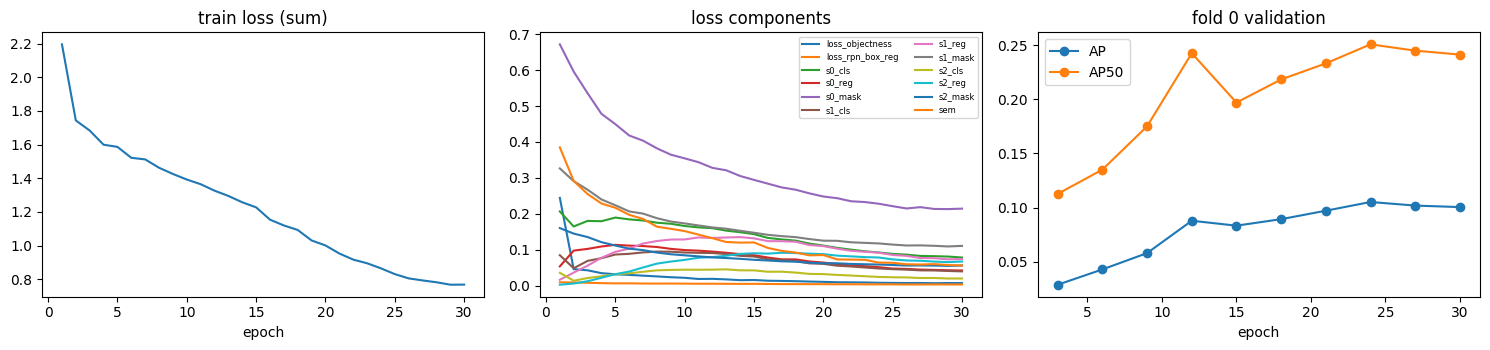

In [10]:
# ---- results table + curves ----
df = pd.DataFrame(RESULTS).T
cols = [c for c in df.columns if c.split("_")[-1] in ("AP", "AP50", "AP75")] + ["best_epoch"]
display(df[cols].round(4))
if len(df) > 1:
    print("mean +/- std over folds"); display(pd.DataFrame({"mean": df[cols].mean(), "std": df[cols].std()}).round(4))
df.to_csv(os.path.join(CFG["OUT_DIR"], "htc_baseline_results.csv"))

fold0 = CFG["FOLDS"][0]; h = pd.DataFrame(MODELS[fold0][4])
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(h.epoch, h.loss); ax[0].set_title("train loss (sum)"); ax[0].set_xlabel("epoch")
for k in [c for c in h.columns if c.endswith(("_cls", "_reg", "_mask")) or c in ("sem", "loss_objectness", "loss_rpn_box_reg")]:
    ax[1].plot(h.epoch, h[k], label=k)
ax[1].set_title("loss components"); ax[1].legend(fontsize=6, ncol=2)
v = h.dropna(subset=["val_AP"]); ax[2].plot(v.epoch, v.val_AP, "o-", label="AP"); ax[2].plot(v.epoch, v.val_AP50, "o-", label="AP50")
ax[2].set_title(f"fold {fold0} validation"); ax[2].legend(); ax[2].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(os.path.join(CFG["OUT_DIR"], "curves.png"), dpi=150); plt.show()

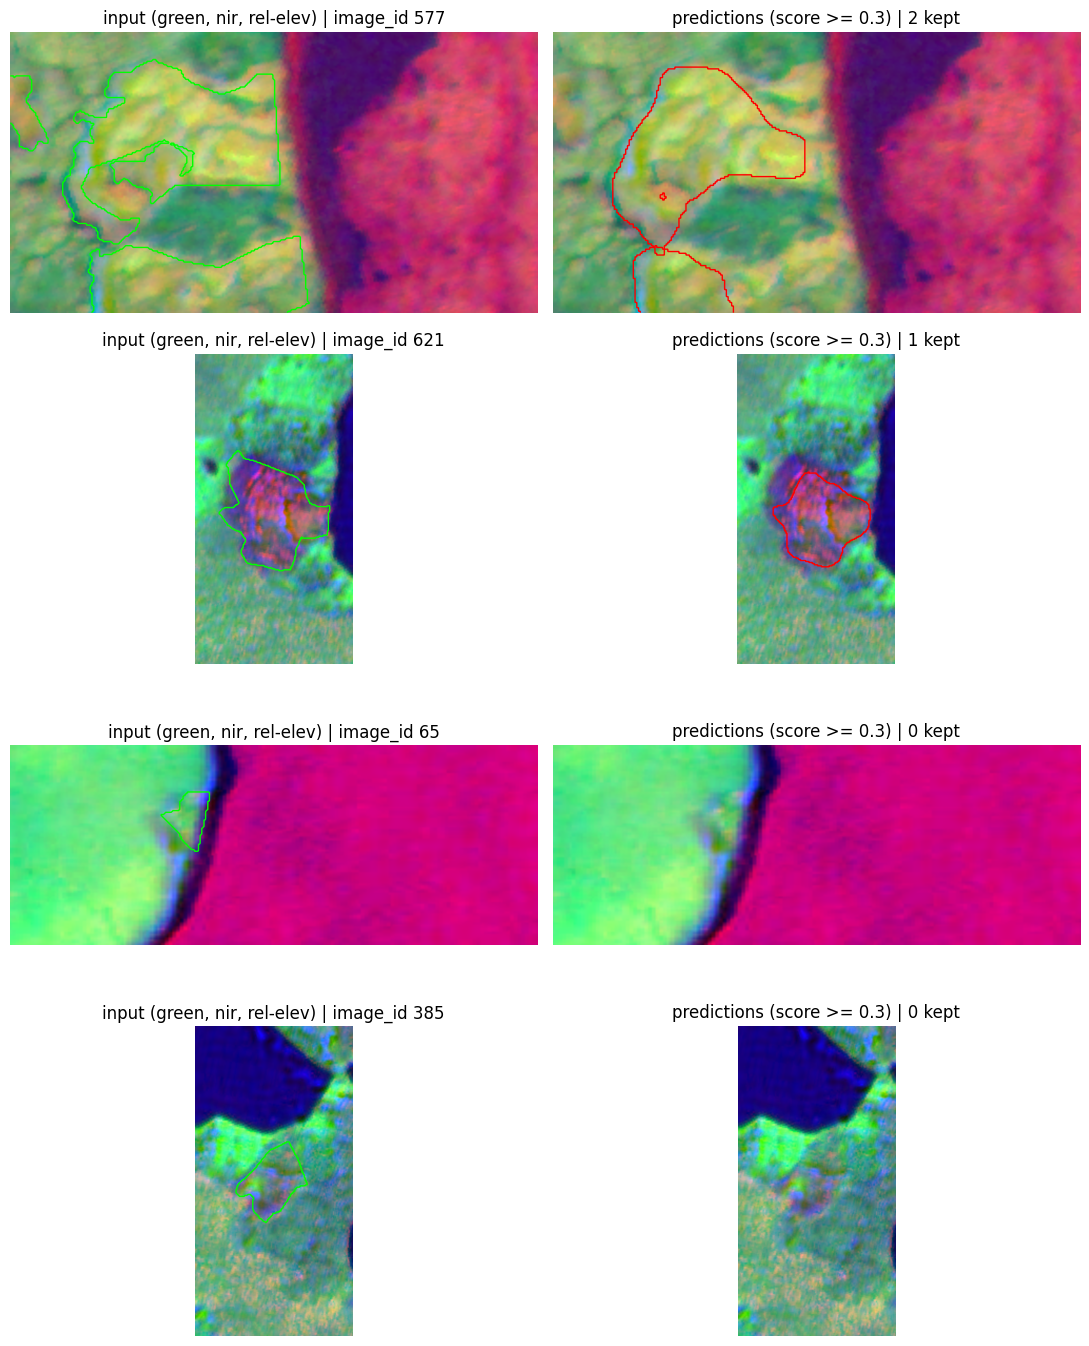

In [11]:
# ---- qualitative check on validation chips (GT = green, prediction = red) ----
@torch.no_grad()
def show_predictions(fold, split="val", n=4, thr=0.3):
    model, sp, ds, stats, _ = MODELS[fold]; model.eval(); d = ds[split]
    fig, axs = plt.subplots(n, 2, figsize=(11, 3.4 * n))
    for r, i in enumerate(random.sample(range(len(d)), min(n, len(d)))):
        img, tg = d[i]; im, sizes, tgs = collate([(img, tg)])
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=CFG["AMP"] and device.type == "cuda"):
            o = model.predict(im.to(device), sizes, [tg["meta"]], CFG["SCORE_THR"], CFG["NMS_THR"], CFG["MAX_DET"])[0]
        vis = img.permute(1, 2, 0).numpy(); vis = (vis - vis.min((0, 1))) / (np.ptp(vis, (0, 1)) + 1e-6)
        h, w = vis.shape[:2]
        pm = F.interpolate(o["masks"][None].float().cpu(), size=(h, w), mode="nearest")[0] > 0.5 if len(o["scores"]) else torch.zeros(0, h, w)
        sc = o["scores"].float().cpu()
        axs[r, 0].imshow(vis); axs[r, 0].set_title(f"input (green, nir, rel-elev) | image_id {tg['meta']['image_id']}")
        for m in tg["masks"].numpy(): axs[r, 0].contour(m, [0.5], colors="lime", linewidths=1)
        axs[r, 1].imshow(vis)
        for m, s in zip(pm.numpy(), sc.numpy()):
            if s >= thr: axs[r, 1].contour(m.astype(float), [0.5], colors="red", linewidths=1)
        axs[r, 1].set_title(f"predictions (score >= {thr}) | {int((sc >= thr).sum())} kept"); [a.axis("off") for a in axs[r]]
    plt.tight_layout(); plt.show()
show_predictions(CFG["FOLDS"][0])

In [12]:
# ---- official test submission (138 hidden-label chips) with the best checkpoint of one fold ----
SUB_FOLD = CFG["FOLDS"][0]
ck = torch.load(os.path.join(CFG["OUT_DIR"], f"fold_{SUB_FOLD}", "best.pt"), map_location=device)
model = build_model(); model.load_state_dict(ck["model"]); model.eval()

man = pd.read_csv(os.path.join(CR_ROOT, "metadata", "test_manifest.csv"))
infos = [dict(id=int(r.image_id), file_name=r.file_name, width=int(r.width), height=int(r.height)) for r in man.itertuples()]
index = build_index(os.path.join(CR_ROOT, "test", "images"))
test_ds = RTSData(infos, index, BAND_IDX, ck["stats"], coco=None, train=False)
preds = run_inference(model, test_ds)
sub_path = os.path.join(CFG["OUT_DIR"], "submission.json")
with open(sub_path, "w") as f: json.dump(preds, f)
print("predictions:", len(preds), "| images with >=1 prediction:", len({p["image_id"] for p in preds}), "/", len(infos))

tools = os.path.join(CR_ROOT, "tools")
r = subprocess.run([sys.executable, "validate_submission.py", "--submission", sub_path,
                    "--manifest", os.path.join(CR_ROOT, "metadata", "test_manifest.csv")],
                   cwd=tools, capture_output=True, text=True)
print(r.stdout, r.stderr)

predictions: 337 | images with >=1 prediction: 138 / 138
predictions=337
images_with_predictions=138
validation=ok
 


### Ablation switches (reproduce the paper's Table 2 on RTS)
Run the training cell three times, changing only these in `CFG`, and compare `val_AP` / `test_AP` on the same grouped folds:

| run | `USE_SEM` | `INFO_FLOW` | corresponds to |
|---|---|---|---|
| A | False | False | Cascade Mask R-CNN + interleaved execution |
| B | False | True  | + mask information flow |
| C | True  | True  | **full HTC (default)** |

Notes: set `FOLDS=[0,1,2,3,4]` for the final baseline number (mean +/- std over folds). If you hit CUDA OOM lower `BATCH` to 2 or `MIN_SIZE` to 384.